# Medicare Part D Prescription Claims: Refill Analysis and Simulated Non-Adherence Prediction

**Project:** Data engineering, refill-behavior analysis, and predictive-model development  
**Environment:** PyCharm · Python 3.11.3 · Jupyter · Docker/PostgreSQL 18.3  
**Source:** CMS DE-SynPUF Sample 1, 2008–2010 (synthetic Part D Prescription Drug Events)

## Business question: Can prescription dispensing history help identify beneficiaries who may be at risk of future medication non-adherence?

Completed an end-to-end machine learning proof of concept, including PostgreSQL ingestion, data-quality assessment, refill analysis, feature engineering, simulated target generation, model development, validation, and final testing.

The predictive models were trained against simulated non-adherence outcomes. Actual future PDC labels and a clinically validated medication-adherence prediction model have not been developed.

**References:** [CMS DE-SynPUF](https://www.cms.gov/data-research/statistics-trends-and-reports/medicare-claims-synthetic-public-use-files/cms-2008-2010-data-entrepreneurs-synthetic-public-use-file-de-synpuf) · [ResDAC Prescription Drug Events](https://www.resdac.org/cms-data/files/pde)

---
# Pre-section | Environment, connection, and data preparation

*Run this section before the analysis. I kept the infrastructure details here so the presentation can focus on methods and results. The raw PostgreSQL data remains untouched; staging transformations are views.*

### P0.1 Imports and interpreter verification

All notebook imports are centralized below. The project uses its existing Python `.venv`; no package installation is performed during the presentation.

In [68]:
import csv
import os
import sys
from getpass import getpass
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix

print(f"Python: {sys.version.split()[0]}")
print(f"Interpreter: {sys.executable}")
print(f"Pandas: {pd.__version__} | Scikit-Learn: {sklearn.__version__} | Psycopg: {psycopg.__version__}")

Python: 3.11.3
Interpreter: /Users/chi-chi/PycharmProjects/Medication_Non_Adherence_Prediction_Model/.venv/bin/python
Pandas: 3.1.1 | Scikit-Learn: 1.9.1 | Psycopg: 3.3.9


### P0.2 Connect to PostgreSQL

The Docker container is `data-sci`, exposed on `localhost:5432`; the database is `medicare_project`. I read the password at runtime instead of storing it in the notebook.

In [69]:
DB_USER = os.getenv("PGUSER", "postgres")
DB_HOST = os.getenv("PGHOST", "localhost")
DB_PORT = int(os.getenv("PGPORT", "5432"))
DB_NAME = os.getenv("PGDATABASE", "medicare_project")
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD") or getpass("PostgreSQL password: ")

DATABASE_URL = URL.create(
    "postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
engine = create_engine(DATABASE_URL, pool_pre_ping=True)

with engine.connect() as connection:
    db_info = dict(connection.execute(text("""
        SELECT current_database() AS database_name,
               current_user AS database_user,
               current_setting('server_version') AS server_version
    """)).mappings().one())

assert db_info["database_name"] == "medicare_project", db_info
print("Connected:", db_info)

Connected: {'database_name': 'medicare_project', 'database_user': 'postgres', 'server_version': '18.3 (Debian 18.3-1.pgdg13+1)'}


### P0.3 Identify and inspect the source CSV

I checked the file path, schema, and first five rows without loading the full 405 MB source into memory. Identifiers are read as strings to preserve leading zeros.

In [70]:
csv_path = Path("data/raw/DE1_0_2008_to_2010_Prescription_Drug_Events_Sample_1.csv")
expected_columns = [
    "DESYNPUF_ID", "PDE_ID", "SRVC_DT", "PROD_SRVC_ID",
    "QTY_DSPNSD_NUM", "DAYS_SUPLY_NUM", "PTNT_PAY_AMT", "TOT_RX_CST_AMT",
]

if not csv_path.is_file():
    raise FileNotFoundError(f"CMS data not found at: {csv_path.resolve()}")
with csv_path.open("r", newline="", encoding="utf-8-sig") as file:
    actual_columns = next(csv.reader(file))
assert actual_columns == expected_columns, f"Unexpected CSV header: {actual_columns}"

df_sample = pd.read_csv(
    csv_path,
    nrows=5,
    dtype={"DESYNPUF_ID": "string", "PDE_ID": "string",
           "SRVC_DT": "string", "PROD_SRVC_ID": "string"},
)
print(f"CSV located: {csv_path} ({csv_path.stat().st_size / 1024**2:.2f} MB)")
print("Source columns:", list(df_sample.columns))
display(df_sample)

CSV located: data/raw/DE1_0_2008_to_2010_Prescription_Drug_Events_Sample_1.csv (405.31 MB)
Source columns: ['DESYNPUF_ID', 'PDE_ID', 'SRVC_DT', 'PROD_SRVC_ID', 'QTY_DSPNSD_NUM', 'DAYS_SUPLY_NUM', 'PTNT_PAY_AMT', 'TOT_RX_CST_AMT']


,DESYNPUF_ID,PDE_ID,SRVC_DT,PROD_SRVC_ID,QTY_DSPNSD_NUM,DAYS_SUPLY_NUM,PTNT_PAY_AMT,TOT_RX_CST_AMT
0,00013D2EFD8E45D1,233664490397622,20080103,00247037252,30.0,20,10.0,120.0
1,00013D2EFD8E45D1,233644490171972,20080105,00223039502,10.0,10,0.0,0.0
2,00013D2EFD8E45D1,233974489116848,20080109,00364724812,120.0,30,10.0,110.0
3,00013D2EFD8E45D1,233574491083209,20080123,00179180672,30.0,30,0.0,240.0
4,00013D2EFD8E45D1,233024491180571,20080124,58016005300,30.0,30,70.0,70.0


### P0.4 Raw schema and idempotent load

I preserved the original eight source columns in a raw table, adding an internal row ID. PostgreSQL `COPY` streams the file in chunks. If the raw table already contains rows, the import is **skipped** to avoid duplication. The load is not designed to silently append a second copy of the dataset.

In [71]:
# Create the raw schema and prescription table
with engine.begin() as connection:

    # Create a schema for raw CMS data
    connection.execute(text("""
        CREATE SCHEMA IF NOT EXISTS raw;
    """))

    # Create the prescription events table
    connection.execute(text("""
        CREATE TABLE IF NOT EXISTS raw.prescription_drug_events (
            source_row_id BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
            desynpuf_id TEXT,
            pde_id TEXT,
            srvc_dt TEXT,
            prod_srvc_id TEXT,
            qty_dspnsd_num TEXT,
            days_suply_num TEXT,
            ptnt_pay_amt TEXT,
            tot_rx_cst_amt TEXT
        );
    """))

print("Raw prescription events table created successfully!")

Raw prescription events table created successfully!


In [72]:
expected_columns = [
    "DESYNPUF_ID", "PDE_ID", "SRVC_DT", "PROD_SRVC_ID",
    "QTY_DSPNSD_NUM", "DAYS_SUPLY_NUM", "PTNT_PAY_AMT", "TOT_RX_CST_AMT",
]
assert csv_path.is_file(), f"Source file missing: {csv_path}"
with csv_path.open("r", newline="", encoding="utf-8-sig") as file:
    assert next(csv.reader(file)) == expected_columns, "Unexpected CSV header"

with engine.connect() as connection:
    existing_rows = connection.execute(
        text("SELECT COUNT(*) FROM raw.prescription_drug_events")
    ).scalar_one()

if existing_rows:
    print(f"Skipping COPY: raw table already contains {existing_rows:,} records.")
else:
    copy_sql = """
    COPY raw.prescription_drug_events (
        desynpuf_id, pde_id, srvc_dt, prod_srvc_id,
        qty_dspnsd_num, days_suply_num, ptnt_pay_amt, tot_rx_cst_amt
    ) FROM STDIN WITH (FORMAT CSV, HEADER TRUE)
    """
    start = perf_counter()
    db_connection = engine.raw_connection()
    try:
        with db_connection.cursor() as cursor:
            with cursor.copy(copy_sql) as copy:
                with csv_path.open("rb") as file:
                    while chunk := file.read(4 * 1024 * 1024):
                        copy.write(chunk)
        db_connection.commit()
        print(f"COPY complete in {perf_counter() - start:.1f} seconds")
    except Exception:
        db_connection.rollback()
        raise
    finally:
        db_connection.close()

Skipping COPY: raw table already contains 5,552,421 records.


### P0.5 Typed staging view

The staging view converts dates and numeric fields while **preserving `DAYS_SUPLY_NUM = 0`** in `days_supply_reported`. A separate Boolean flag indicates whether days supply is positive and within 1–999 for an *exploratory coverage calculation*. This is not a CMS claim-validity determination.

I used `CREATE OR REPLACE VIEW` with the existing column structure instead of dropping a view that later analysis objects may depend on.

In [73]:
# P0.5: Create the typed staging view

with engine.begin() as connection:

    # 1. Create the staging schema
    connection.execute(text("""
        CREATE SCHEMA IF NOT EXISTS staging;
    """))

    # 2. Create or replace the staging view
    connection.execute(text("""
        CREATE OR REPLACE VIEW staging.prescription_drug_events AS

        SELECT
            -- Unique source record identifier
            source_row_id,

            -- Medicare beneficiary identifier
            desynpuf_id,

            -- Prescription event identifier
            pde_id,

            -- Convert prescription date from YYYYMMDD to DATE
            TO_DATE(
                NULLIF(srvc_dt, ''),
                'YYYYMMDD'
            ) AS service_date,

            -- Medication product identifier
            prod_srvc_id,

            -- Quantity dispensed
            NULLIF(qty_dspnsd_num, '')::NUMERIC
                AS quantity_dispensed,

            -- Preserve CMS days-supply values, including 0
            NULLIF(days_suply_num, '')::INTEGER
                AS days_supply_reported,

            -- Flag zero-day prescriptions
            (
                NULLIF(days_suply_num, '')::INTEGER = 0
            ) AS days_supply_is_zero,

            -- Exploratory coverage flag: days supply within 1-999
            -- (not a CMS claim-validity determination)
            (
                NULLIF(days_suply_num, '')::INTEGER
                BETWEEN 1 AND 999
            ) AS pdc_coverage_eligible,

            -- Patient prescription payment
            NULLIF(ptnt_pay_amt, '')::NUMERIC
                AS patient_pay_amount,

            -- Total prescription cost
            NULLIF(tot_rx_cst_amt, '')::NUMERIC
                AS total_prescription_cost

        FROM raw.prescription_drug_events;
    """))

print("Staging prescription view created successfully!")
print("Original days-supply values preserved.")
print("PDC eligibility and zero-day flags added.")

Staging prescription view created successfully!
Original days-supply values preserved.
PDC eligibility and zero-day flags added.


### P0.6 Full-load verification

These checks reconcile raw and staging event counts, preserve the zero-day records, and validate beneficiary identifiers, dates, and numerical ranges. The displayed findings below reflect outputs from my prior completed run and should be refreshed if the underlying data changes.

In [74]:
verification_query = """
SELECT
    COUNT(*) AS total_prescriptions,
    COUNT(DISTINCT desynpuf_id) AS unique_beneficiaries,
    COUNT(*) FILTER (
        WHERE days_suply_num = '0'
    ) AS zero_day_prescriptions
FROM raw.prescription_drug_events;
"""

df_verification = pd.read_sql(
    verification_query,
    engine
)

display(df_verification)

,total_prescriptions,unique_beneficiaries,zero_day_prescriptions
0,5552421,99538,117726


In [75]:
sql_staging_check = """
SELECT
    COUNT(*) AS total_prescriptions,

    COUNT(*) FILTER (
        WHERE days_supply_is_zero
    ) AS zero_day_prescriptions,

    COUNT(*) FILTER (
        WHERE pdc_coverage_eligible
    ) AS pdc_eligible_prescriptions,

    COUNT(*) FILTER (
        WHERE NOT pdc_coverage_eligible
           OR pdc_coverage_eligible IS NULL
    ) AS pdc_ineligible_prescriptions

FROM staging.prescription_drug_events;
"""

df_staging_check = pd.read_sql(sql_staging_check, engine)

display(df_staging_check)

,total_prescriptions,zero_day_prescriptions,pdc_eligible_prescriptions,pdc_ineligible_prescriptions
0,5552421,117726,5434695,117726


In [76]:
sql_full_validation = """
SELECT
    COUNT(DISTINCT desynpuf_id) AS unique_beneficiaries,

    MIN(service_date) AS earliest_prescription,
    MAX(service_date) AS latest_prescription,

    COUNT(*) FILTER (
        WHERE service_date IS NULL
           OR service_date NOT BETWEEN
               DATE '2008-01-01' AND DATE '2010-12-31'
    ) AS invalid_dates,

    COUNT(*) FILTER (
        WHERE days_supply_reported IS NULL
           OR days_supply_reported < 0
           OR days_supply_reported > 999
    ) AS out_of_range_days_supply,

    COUNT(*) FILTER (
        WHERE prod_srvc_id IS NULL
           OR TRIM(prod_srvc_id) = ''
    ) AS missing_medication_ids,

    COUNT(*) FILTER (
        WHERE quantity_dispensed < 0
    ) AS negative_quantities

FROM staging.prescription_drug_events;
"""

df_validation = pd.read_sql(sql_full_validation, engine)

display(df_validation)

,unique_beneficiaries,earliest_prescription,latest_prescription,invalid_dates,out_of_range_days_supply,missing_medication_ids,negative_quantities
0,99538,2008-01-01,2010-12-31,0,0,0,0


In [77]:
raw_n = int(df_verification.loc[0, "total_prescriptions"])
staged_n = int(df_staging_check.loc[0, "total_prescriptions"])
raw_zero = int(df_verification.loc[0, "zero_day_prescriptions"])
staged_zero = int(df_staging_check.loc[0, "zero_day_prescriptions"])
assert raw_n == staged_n, (raw_n, staged_n)
assert raw_n == 5_552_421, f"Unexpected raw row count: {raw_n:,}; check import before proceeding"
assert raw_zero == staged_zero, (raw_zero, staged_zero)
assert int(df_staging_check.loc[0, "pdc_eligible_prescriptions"]) + staged_zero == staged_n
print(f"Setup verified: {raw_n:,} raw and staged events; {staged_zero:,} zero-day records preserved.")

Setup verified: 5,552,421 raw and staged events; 117,726 zero-day records preserved.


---
# 1. Source quality | Defining usable coverage

**Question:** What can I reliably infer from the source fields?

I initially inspected 50,000 events and then investigated the entire raw table. The key distinction was between **a source value being allowed** and **that value supporting a coverage-duration calculation**.

In [78]:
# Initial quality screen of 50,000 prescription events

df_quality = pd.read_csv(
    csv_path,
    nrows=50_000,
    dtype={
        "DESYNPUF_ID": "string",
        "PDE_ID": "string",
        "SRVC_DT": "string",
        "PROD_SRVC_ID": "string",
    },
)
df_quality["SRVC_DT"] = pd.to_datetime(
    df_quality["SRVC_DT"], format="%Y%m%d", errors="coerce"
)

print("Rows:", len(df_quality))
print("Missing values:", int(df_quality.isna().sum().sum()))
print("Duplicate PDE IDs:", int(df_quality["PDE_ID"].duplicated().sum()))
print("Invalid dates:", int(df_quality["SRVC_DT"].isna().sum()))
print("Zero days supplied:", int(df_quality["DAYS_SUPLY_NUM"].eq(0).sum()))
print("Negative days supplied:", int(df_quality["DAYS_SUPLY_NUM"].lt(0).sum()))
print("Unique beneficiaries:", df_quality["DESYNPUF_ID"].nunique())
print("Date range:", df_quality["SRVC_DT"].min().date(), "to", df_quality["SRVC_DT"].max().date())
print("Median days supply:", df_quality["DAYS_SUPLY_NUM"].median())

Rows: 50000
Missing values: 0
Duplicate PDE IDs: 0
Invalid dates: 0
Zero days supplied: 998
Negative days supplied: 0
Unique beneficiaries: 954
Date range: 2008-01-01 to 2010-12-31
Median days supply: 30.0


#### Findings — Initial Data Quality Assessment

I began by examining the first 50,000 prescription events
to evaluate data structure and identify potential quality
issues before conducting analysis across the full dataset.

**Key findings:**

- No missing values, duplicate PDE identifiers, or
  invalid prescription dates were identified.
- The median prescription days supply was 30 days.
- 998 records (1.996%) reported zero days supplied.
- The records spanned the full 2008–2010 study period.

**Interpretation:**

Although zero days supplied initially appeared unusual,
CMS documentation identifies zero as an allowable value.
I therefore retained those records and investigated their
impact on medication coverage calculations.

Because this assessment used the first 50,000 records,
I treated the results as preliminary and subsequently
validated data quality across the full PostgreSQL dataset.

In [79]:
sql_zero_day_events = """
SELECT
    COUNT(*) AS total_zero_day_events,

    COUNT(*) FILTER (
        WHERE qty_dspnsd_num::NUMERIC > 0
    ) AS positive_quantity_events,

    COUNT(*) FILTER (
        WHERE tot_rx_cst_amt::NUMERIC > 0
    ) AS positive_cost_events

FROM raw.prescription_drug_events
WHERE days_suply_num::NUMERIC = 0;
"""

df_zero_supply = pd.read_sql(sql_zero_day_events, engine)

display(df_zero_supply)

,total_zero_day_events,positive_quantity_events,positive_cost_events
0,117726,101200,97467


#### Findings — Zero-Day Supply Investigation

Across the full dataset, I identified 117,726 prescription
events (2.12%) reporting zero days supplied.

Of these:
- 86.0% reported a positive dispensing quantity.
- 82.8% reported a positive prescription cost.

These findings reinforced the need to distinguish
valid source values from values suitable for
medication coverage calculations.

**Decision:** I preserved the original records and
introduced separate flags to identify zero-day events
and records with positive days supply.

This approach maintains data integrity while allowing
me to evaluate how uncertain coverage affects
downstream adherence calculations.

---
# 2. Refill timing | From SQL sequences to stockpiling

**Question:** Can I derive meaningful refill intervals from individual PDE records?

I started by matching exact product codes (`NDC11`) and using PostgreSQL `LAG()` to order fills. I then tested a concrete three-fill history before scaling any gap calculation.

In [80]:
sql_ndc11_repeats = """
SELECT
    desynpuf_id,
    prod_srvc_id,
    COUNT(*) AS total_fills,
    MIN(service_date) AS first_fill,
    MAX(service_date) AS last_fill

FROM staging.prescription_drug_events

WHERE pdc_coverage_eligible IS TRUE

GROUP BY
    desynpuf_id,
    prod_srvc_id

HAVING COUNT(*) >= 2

ORDER BY
    total_fills DESC,
    desynpuf_id,
    prod_srvc_id

"""

df_repeated_fills = pd.read_sql(sql_ndc11_repeats, engine)


# Summarize repeated prescriptions by NDC11
ndc11_summary = pd.DataFrame({
    "Metric": [
        "Groups with 2+ fills",
        "Groups with 3+ fills",
        "Maximum fills per group"
    ],
    "Value": [
        len(df_repeated_fills),
        (df_repeated_fills["total_fills"] >= 3).sum(),
        df_repeated_fills["total_fills"].max()
    ]
})

display(ndc11_summary)

# Distribution of repeated fills
ndc11_distribution = (
    df_repeated_fills["total_fills"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Fills")
    .reset_index(name="Number of Groups")
)

display(ndc11_distribution)

,Metric,Value
0,Groups with 2+ fills,3213
1,Groups with 3+ fills,7
2,Maximum fills per group,3


,Number of Fills,Number of Groups
0,2,3206
1,3,7


#### Findings — Prescription Refill Continuity (NDC11)

I grouped prescription events by beneficiary and the
full 11-digit National Drug Code (NDC) to identify
repeated fills of the same medication product.

**Key findings:**
- 3,213 beneficiary–product combinations had at least
  two prescription events.
- Only seven combinations contained three fills.
- No combination contained more than three fills.

**Interpretation:**

Repeated prescriptions with identical NDC11 identifiers
were uncommon in the synthetic dataset.

This raised an important modeling consideration:
grouping strictly by NDC11 may fragment refill histories
when the same medication is dispensed in different
package sizes.

I decided to investigate medication grouping at the
nine-digit product level before developing patient-level
adherence features.

**Limitation:** CMS DE-SynPUF drug identifiers have
been modified for disclosure protection, so repeated
product codes do not establish verified therapeutic
continuity.

In [81]:
# Select a beneficiary with three recorded fills
beneficiary_id = "76F99DA321757C69"
medication_id = "54868540600"

sql_three_fill_history = text("""
WITH refill_history AS (
    SELECT
        desynpuf_id,
        prod_srvc_id,
        service_date,
        days_supply_reported,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, prod_srvc_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date,

        LAG(days_supply_reported) OVER (
            PARTITION BY desynpuf_id, prod_srvc_id
            ORDER BY service_date, source_row_id
        ) AS previous_days_supply

    FROM staging.prescription_drug_events

    WHERE desynpuf_id = :beneficiary_id
      AND prod_srvc_id = :medication_id
      AND pdc_coverage_eligible IS TRUE
)

SELECT
    service_date,
    days_supply_reported,
    previous_fill_date,
    previous_days_supply,

    -- Calculate days between fills
    service_date - previous_fill_date
        AS days_between_fills,

    -- Expected next refill date
    previous_fill_date + previous_days_supply
        AS expected_refill_date,

    -- Calculate estimated refill gap
    CASE
        WHEN previous_fill_date IS NULL
        THEN NULL

        ELSE GREATEST(
            0,
            service_date -
            (previous_fill_date + previous_days_supply)
        )
    END AS refill_gap_days

FROM refill_history

ORDER BY service_date;
""")

df_three_fills = pd.read_sql(sql_three_fill_history,
    engine,
    params={
        "beneficiary_id": beneficiary_id,
        "medication_id": medication_id
    }
)

display(df_three_fills)

,service_date,days_supply_reported,previous_fill_date,previous_days_supply,days_between_fills,expected_refill_date,refill_gap_days
0,2008-01-14,90,None,NaN,NaN,None,NaN
1,2008-03-29,30,2008-01-14,90.0,75.0,2008-04-13,0.0
2,2008-05-07,30,2008-03-29,30.0,39.0,2008-04-28,9.0


**Finding — naive gaps:** In one sequence, the beneficiary filled **90 days on January 14, 2008**, **30 days on March 29**, and **30 days on May 7**. A simple comparison between consecutive fills produced a **9-day gap** before the third fill. That ignored medication remaining from the earlier 90-day supply.

In [82]:
# Select the columns needed for coverage calculations
df_stockpile = df_three_fills[
    ["service_date", "days_supply_reported"]
].copy()

# Ensure dates use the correct data type
df_stockpile["service_date"] = pd.to_datetime(
    df_stockpile["service_date"]
)

# Sort prescriptions chronologically
df_stockpile = df_stockpile.sort_values(
    "service_date"
).reset_index(drop=True)

# Track the date when medication supply runs out
coverage_end = None

results = []

for _, row in df_stockpile.iterrows():

    fill_date = row["service_date"]
    days_supply = int(row["days_supply_reported"])

    if coverage_end is None:
        # First prescription
        carryover_days = 0
        adjusted_gap = None
        coverage_start = fill_date

    else:
        # Days without supply before this fill
        adjusted_gap = max(
            0,
            (fill_date - coverage_end).days
        )

        # Unused medication from previous fills
        carryover_days = max(
            0,
            (coverage_end - fill_date).days
        )

        # Extend coverage when medication remains
        coverage_start = max(fill_date, coverage_end)

    # Update expected coverage end
    coverage_end = coverage_start + pd.Timedelta(
        days=days_supply
    )

    results.append({
        "fill_date": fill_date.date(),
        "days_supply": days_supply,
        "carryover_days": carryover_days,
        "adjusted_gap_days": adjusted_gap,
        "next_expected_refill": coverage_end.date()
    })

# Convert results into a DataFrame
df_adjusted_refills = pd.DataFrame(results)

display(df_adjusted_refills)

,fill_date,days_supply,carryover_days,adjusted_gap_days,next_expected_refill
0,2008-01-14,90,0,NaN,2008-04-13
1,2008-03-29,30,15,0.0,2008-05-13
2,2008-05-07,30,6,0.0,2008-06-12


#### Findings — Refill Gaps and Medication Stockpiling

I initially calculated refill gaps using the time between
consecutive prescriptions and the previous days supplied.

The initial calculation identified a 9-day gap for the
May 7, 2008 prescription.

However, the beneficiary had refilled 15 days early in
March, leaving medication available from the earlier fill.

After adjusting for unused medication carried forward:

- The March refill had 15 days of remaining supply.
- The May refill had 6 days of remaining supply.
- The estimated 9-day gap decreased to 0 days.

**Conclusion**

Accounting for medication stockpiling materially changed
the calculated refill gap. Without this adjustment, the
model could incorrectly interpret early refill behavior
as an interruption in medication availability.

I incorporated carryover into the exploratory calculation
to improve the accuracy of refill-timing features.

This remains a simplified same-product calculation and
does not establish actual medication consumption or
reproduce the full CMS PDC methodology.

---
# 3. Medication grouping | NDC11 versus NDC9

**Question:** Does removing the two package digits improve repeated-fill coverage?

I derived an NDC9 prefix and compared repeated product sequences. In the standard 11-digit NDC configuration, the last two digits identify the package; however, the **synthetic DE-SynPUF drug identifiers were modified**, so the grouping is an engineering hypothesis—not verified clinical equivalence.

In [83]:
# Create a staging view with an additional NDC9 column
with engine.begin() as connection:

    connection.execute(text("""
        CREATE OR REPLACE VIEW
        staging.prescription_drug_events_ndc9 AS

        SELECT
            *,

            -- Extract the first 9 digits of NDC11
            CASE
                WHEN TRIM(prod_srvc_id) ~ '^[0-9]{11}$'
                THEN LEFT(TRIM(prod_srvc_id), 9)
                ELSE NULL
            END AS ndc9_product_id

        FROM staging.prescription_drug_events;
    """))

print("NDC9 staging view created successfully!")

NDC9 staging view created successfully!


In [84]:
sql_ndc9_validation = """
SELECT
    desynpuf_id,
    prod_srvc_id,
    ndc9_product_id,
    RIGHT(prod_srvc_id, 2) AS package_code,
    service_date,
    days_supply_reported

FROM staging.prescription_drug_events_ndc9

WHERE desynpuf_id = '70E3B962B5448883'
  AND ndc9_product_id = '580160877'

ORDER BY service_date;
"""

df_ndc9_validation = pd.read_sql(
    sql_ndc9_validation,
    engine
)

display(df_ndc9_validation)

print("Total prescription events:", len(df_ndc9_validation))
print(
    "Distinct packaging codes:",
    df_ndc9_validation["package_code"].nunique()
)

,desynpuf_id,prod_srvc_id,ndc9_product_id,package_code,service_date,days_supply_reported
0,70E3B962B5448883,58016087704,580160877,04,2008-04-05,30
1,70E3B962B5448883,58016087732,580160877,32,2008-08-17,30
2,70E3B962B5448883,58016087771,580160877,71,2009-01-15,50
3,70E3B962B5448883,58016087750,580160877,50,2009-09-18,30
4,70E3B962B5448883,58016087736,580160877,36,2010-08-18,60
5,70E3B962B5448883,58016087799,580160877,99,2010-11-29,90


Total prescription events: 6
Distinct packaging codes: 6


#### Findings — NDC9 Medication Grouping

I evaluated whether removing the two-digit packaging
component of the NDC would improve prescription
history continuity.

For one beneficiary, I identified six prescription
events with different NDC11 identifiers that shared
the same nine-digit product prefix.

**Key findings:**
- Six prescription events shared NDC9 `580160877`.
- All six had different package identifiers.
- Exact NDC11 matching would treat each event as
  a separate medication sequence.

**Conclusion:**

Grouping by NDC9 improved the ability to identify
related prescription records within the synthetic
dataset.

However, because CMS modified medication identifiers
for disclosure protection, I treated NDC9 as an
exploratory grouping variable rather than a
clinically validated medication identifier.

In [85]:
sql_ndc9_repeats = """
SELECT
    desynpuf_id,
    ndc9_product_id,

    COUNT(*) AS total_fills,

    COUNT(DISTINCT prod_srvc_id)
        AS distinct_ndc11_codes,

    MIN(service_date) AS first_fill,
    MAX(service_date) AS last_fill

FROM staging.prescription_drug_events_ndc9

WHERE pdc_coverage_eligible IS TRUE
  AND ndc9_product_id IS NOT NULL

GROUP BY
    desynpuf_id,
    ndc9_product_id

HAVING COUNT(*) >= 2

ORDER BY total_fills DESC;
"""

df_ndc9_repeats = pd.read_sql(
    sql_ndc9_repeats,
    engine
)

print("NDC9 Refill Analysis")
ndc9_summary = pd.DataFrame({
    "Metric": [
        "Groups with 2+ fills",
        "Groups with 3+ fills",
        "Maximum fills per group"
    ],
    "Value": [
        len(df_ndc9_repeats),
        (df_ndc9_repeats["total_fills"] >= 3).sum(),
        df_ndc9_repeats["total_fills"].max()
    ]
})

display(ndc9_summary)

# Distribution of repeated fills
ndc9_distribution = (
    df_ndc9_repeats["total_fills"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Fills")
    .reset_index(name="Number of Groups")
)

display(ndc9_distribution)

NDC9 Refill Analysis


,Metric,Value
0,Groups with 2+ fills,28097
1,Groups with 3+ fills,1057
2,Maximum fills per group,6


,Number of Fills,Number of Groups
0,2,27040
1,3,991
2,4,62
3,5,3
4,6,1


#### Findings — NDC11 vs. NDC9 Grouping

I compared repeated prescription patterns using the
complete 11-digit NDC and the derived 9-digit
product identifier.

**Key findings:**

| Metric | NDC11 | NDC9 |
|---|---:|---:|
| Groups with 2+ fills | 3,213 | 28,097 |
| Groups with 3+ fills | 7 | 1,057 |
| Maximum fills per group | 3 | 6 |

**Interpretation:**

Grouping by NDC9 increased the number of beneficiary-product
combinations with repeated fills by approximately 8.7 times.

This demonstrated that the packaging portion of the
NDC could fragment prescription histories when using
exact product matching.

However, most NDC9 groups still contained only two fills,
and the synthetic product identifiers do not establish
verified medication equivalence.

**Conclusion:**

NDC9 provided a more useful exploratory grouping
strategy than NDC11 for analyzing refill patterns.

I retained the grouping for further analysis while
recognizing that a validated therapeutic-class mapping
would be necessary for clinically meaningful PDC modeling.

In [86]:
sql_ndc9_history = text("""
SELECT
    desynpuf_id,
    ndc9_product_id,
    prod_srvc_id,

    -- Extract packaging identifier
    RIGHT(prod_srvc_id, 2) AS package_code,

    service_date,
    quantity_dispensed,
    days_supply_reported,
    patient_pay_amount

FROM staging.prescription_drug_events_ndc9

WHERE desynpuf_id = :beneficiary_id
  AND ndc9_product_id = :ndc9
  AND pdc_coverage_eligible IS TRUE

ORDER BY
    service_date,
    source_row_id;
""")

df_ndc9_history = pd.read_sql(sql_ndc9_history,
    engine,
    params={
        "beneficiary_id": "70E3B962B5448883",
        "ndc9": "580160877"
    }
)

display(df_ndc9_history)

,desynpuf_id,ndc9_product_id,prod_srvc_id,package_code,service_date,quantity_dispensed,days_supply_reported,patient_pay_amount
0,70E3B962B5448883,580160877,58016087704,04,2008-04-05,30.0,30,10.0
1,70E3B962B5448883,580160877,58016087732,32,2008-08-17,30.0,30,10.0
2,70E3B962B5448883,580160877,58016087771,71,2009-01-15,60.0,50,0.0
3,70E3B962B5448883,580160877,58016087750,50,2009-09-18,30.0,30,0.0
4,70E3B962B5448883,580160877,58016087736,36,2010-08-18,30.0,60,20.0
5,70E3B962B5448883,580160877,58016087799,99,2010-11-29,30.0,90,0.0


#### Findings — Individual NDC9 Prescription History

I examined a beneficiary with six prescription events
sharing the same NDC9 identifier.

All six events had different package codes, confirming
that NDC9 grouping captured records that exact NDC11
matching would have separated.

The records also showed variation in prescription
dates, days supplied, and patient payments.

**Conclusion:**

While NDC9 improved prescription grouping, I still
needed to determine whether the time between fills
supported meaningful medication continuity.

In [87]:
sql_ndc9_gap_history = text("""
WITH refill_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        prod_srvc_id,
        service_date,
        days_supply_reported,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date,

        LAG(days_supply_reported) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_days_supply

    FROM staging.prescription_drug_events_ndc9

    WHERE desynpuf_id = :beneficiary_id
      AND ndc9_product_id = :ndc9
      AND pdc_coverage_eligible IS TRUE
)

SELECT
    prod_srvc_id,
    service_date,
    days_supply_reported,
    previous_fill_date,
    previous_days_supply,

    -- Number of days between consecutive fills
    service_date - previous_fill_date
        AS days_between_fills,

    -- Preliminary refill gap calculation
    CASE
        WHEN previous_fill_date IS NULL THEN NULL
        ELSE GREATEST(
            0,
            (service_date - previous_fill_date)
            - previous_days_supply
        )
    END AS estimated_refill_gap

FROM refill_history

ORDER BY service_date;
""")

df_ndc9_gaps = pd.read_sql(sql_ndc9_gap_history,
    engine,
    params={
        "beneficiary_id": "70E3B962B5448883",
        "ndc9": "580160877"
    }
)

display(df_ndc9_gaps)

,prod_srvc_id,service_date,days_supply_reported,previous_fill_date,previous_days_supply,days_between_fills,estimated_refill_gap
0,58016087704,2008-04-05,30,None,NaN,NaN,NaN
1,58016087732,2008-08-17,30,2008-04-05,30.0,134.0,104.0
2,58016087771,2009-01-15,50,2008-08-17,30.0,151.0,121.0
3,58016087750,2009-09-18,30,2009-01-15,50.0,246.0,196.0
4,58016087736,2010-08-18,60,2009-09-18,30.0,334.0,304.0
5,58016087799,2010-11-29,90,2010-08-18,60.0,103.0,43.0


#### Findings — NDC9 Refill Gap Analysis

I calculated refill intervals for a beneficiary with six
prescription events sharing the same NDC9 identifier.

**Key findings:**
- Refill intervals ranged from 103 to 334 days.
- Estimated gaps ranged from 43 to 304 days.
- Total estimated gaps between recorded fills were 768 days.

**Interpretation:**

Although NDC9 grouping increased the number of repeated
prescriptions, the intervals were often substantially
longer than the reported days supplied.

This raised concerns about whether these events represented
a continuous medication regimen.

**Conclusion:**

I determined that NDC9 grouping improved the availability
of refill sequences but was insufficient on its own to
establish clinically meaningful medication adherence.

I needed to evaluate refill continuity across the entire
dataset before constructing predictive model targets.

---
# 4. Feasibility | Can these records support adherence labels?

**Question:** Are repeated histories frequent enough to support the proposed 180-day history and 90-day target?

I measured refill intervals and the proportion of eligible beneficiaries with any NDC9 repeats, then examined the implications for supervised modeling.

In [88]:
sql_interval_distribution = """
WITH prescription_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        service_date,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date

    FROM staging.prescription_drug_events_ndc9

    WHERE pdc_coverage_eligible IS TRUE
      AND ndc9_product_id IS NOT NULL
),

refill_intervals AS (
    SELECT
        service_date - previous_fill_date
            AS days_between_fills

    FROM prescription_history

    WHERE previous_fill_date IS NOT NULL
)

SELECT
    COUNT(*) AS total_refill_pairs,

    COUNT(*) FILTER (
        WHERE days_between_fills = 0
    ) AS same_day_pairs,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 1 AND 30
    ) AS intervals_1_30_days,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 31 AND 90
    ) AS intervals_31_90_days,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 91 AND 180
    ) AS intervals_91_180_days,

    COUNT(*) FILTER (
        WHERE days_between_fills > 180
    ) AS intervals_over_180_days

FROM refill_intervals;
"""

df_refill_distribution = pd.read_sql(sql_interval_distribution, engine)

display(df_refill_distribution)

,total_refill_pairs,same_day_pairs,intervals_1_30_days,intervals_31_90_days,intervals_91_180_days,intervals_over_180_days
0,29225,32,1894,3795,5095,18409


#### Findings — Refill Continuity Across the Dataset

I evaluated the time between consecutive prescription
events grouped by beneficiary and NDC9 identifier.

**Key findings:**

- Identified 29,225 consecutive prescription pairs.
- 19.6% of pairs occurred within 90 days, including
  same-day events.
- 17.4% occurred between 91 and 180 days.
- 63.0% were separated by more than 180 days.

**Interpretation:**

Although NDC9 grouping increased the number of repeated
prescriptions, most intervals were longer than 180 days.

This introduced uncertainty about whether these events
represented continuous medication treatment.

**Conclusion:**

I determined that improving medication grouping alone
was insufficient to produce reliable adherence labels.

Before training a predictive model, I needed to evaluate
whether enough beneficiaries had repeated prescriptions
within a reasonable observation window.

The analysis also highlighted the importance of
distinguishing prescription refill patterns from
confirmed medication non-adherence.

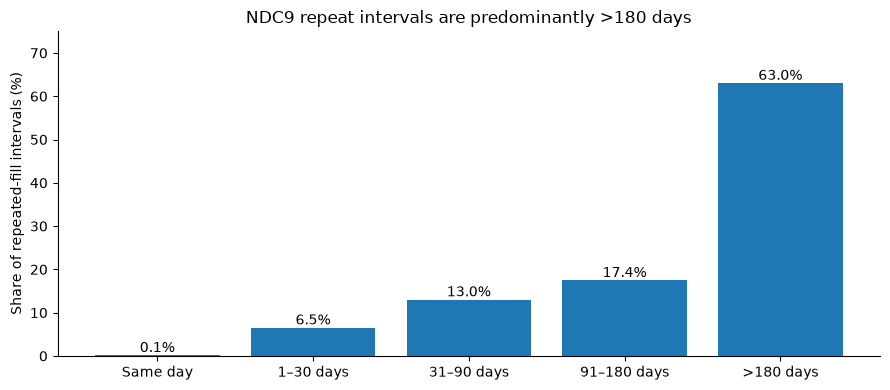

In [89]:
# Distribution of intervals between consecutive NDC9 events
row = df_refill_distribution.iloc[0]
labels = ["Same day", "1–30 days", "31–90 days", "91–180 days", ">180 days"]
counts = [
    row["same_day_pairs"],
    row["intervals_1_30_days"],
    row["intervals_31_90_days"],
    row["intervals_91_180_days"],
    row["intervals_over_180_days"],
]
total = sum(counts)
shares = [100 * value / total for value in counts]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, shares)
ax.set_ylabel("Share of repeated-fill intervals (%)")
ax.set_title("NDC9 repeat intervals are predominantly >180 days")
ax.set_ylim(0, max(shares) + 12)
for bar, share in zip(bars, shares):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            f"{share:.1f}%", ha="center", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Finding — interval distribution:** Across **29,225** consecutive NDC9 pairs, **18,409 (63.0%)** were more than 180 days apart; **5,721 (19.6%)** were within 90 days, including same-day pairs.

In [90]:
sql_beneficiary_continuity = """
WITH prescription_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        service_date,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date

    FROM staging.prescription_drug_events_ndc9

    WHERE pdc_coverage_eligible IS TRUE
      AND ndc9_product_id IS NOT NULL
),

beneficiary_summary AS (
    SELECT
        desynpuf_id,

        COUNT(*) FILTER (
            WHERE previous_fill_date IS NOT NULL
        ) AS repeated_fill_pairs,

        COUNT(*) FILTER (
            WHERE service_date - previous_fill_date
                  BETWEEN 1 AND 90
        ) AS repeated_pairs_90d,

        COUNT(*) FILTER (
            WHERE service_date - previous_fill_date
                  BETWEEN 1 AND 180
        ) AS repeated_pairs_180d

    FROM prescription_history

    GROUP BY desynpuf_id
)

SELECT
    COUNT(*) AS total_beneficiaries,

    COUNT(*) FILTER (
        WHERE repeated_fill_pairs > 0
    ) AS beneficiaries_with_repeats,

    COUNT(*) FILTER (
        WHERE repeated_pairs_90d > 0
    ) AS beneficiaries_with_90d_repeats,

    COUNT(*) FILTER (
        WHERE repeated_pairs_180d > 0
    ) AS beneficiaries_with_180d_repeats

FROM beneficiary_summary;
"""

df_beneficiary_continuity = pd.read_sql(sql_beneficiary_continuity,
    engine
)

display(df_beneficiary_continuity)

,total_beneficiaries,beneficiaries_with_repeats,beneficiaries_with_90d_repeats,beneficiaries_with_180d_repeats
0,99393,20010,5194,9111


#### Findings — Beneficiary-Level Refill Continuity

I evaluated prescription continuity at the beneficiary
level to determine whether the dataset contained
sufficient longitudinal history for adherence modeling.

**Key findings:**

- 99,393 beneficiaries had usable prescription events.
- 20.1% had at least one repeated NDC9 prescription.
- 9.2% had a repeat within 180 days.
- Only 5.2% had a repeat within 90 days.

**Conclusion:**

Although NDC9 grouping improved the number of repeated
prescription sequences, relatively few beneficiaries
had repeated fills within shorter observation windows.

Combined with the limitations of the synthetic drug
identifiers, these results indicated that the dataset
alone could not support clinically validated PDC labels
using the current grouping strategy.

I decided to preserve the CMS data for feature
engineering and use a separately identified simulated
adherence outcome if necessary for demonstrating the
supervised machine learning pipeline.

---
# 5. Feature engineering | Building the modeling dataset

**Objective:** Transform historical prescription activity into beneficiary-level features for predicting medication non-adherence.

I used a 180-day observation window to engineer features related to prescription frequency, medication burden, refill timing, days supplied, and patient costs. I aggregated these features at the beneficiary level and included only information available before the prediction date to prevent data leakage.

### 5.1 Historical Prescription Features

I constructed a beneficiary-level feature dataset using
prescription events from the 180 days preceding
July 1, 2010.

The initial features captured:

- Prescription frequency
- Medication product diversity (NDC9 vs NDC11)
- Average days supplied
- Average patient payment
- Number of zero-day supply events
- Days since the most recent prescription

All features were derived from records before the
prediction date to prevent future-data leakage.

NDC9 represents an exploratory product grouping,
not a validated therapeutic class.

In [91]:
# Section 5.1 — Historical prescription features

sql_patient_features_180d = """
WITH historical_prescriptions AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        prod_srvc_id,
        service_date,
        days_supply_reported,
        days_supply_is_zero,
        pdc_coverage_eligible,
        patient_pay_amount

    FROM staging.prescription_drug_events_ndc9

    WHERE service_date >= DATE '2010-07-01' - 180
      AND service_date < DATE '2010-07-01'
)

SELECT
    desynpuf_id,

    COUNT(*) AS total_prescriptions_180d,

    COUNT(DISTINCT ndc9_product_id)
        AS distinct_ndc9_180d,

    COUNT(DISTINCT prod_srvc_id)
    AS distinct_ndc11_180d,

    ROUND(
        AVG(days_supply_reported)
        FILTER (
            WHERE pdc_coverage_eligible IS TRUE
        ), 2
    ) AS avg_days_supply_180d,

    ROUND(
        AVG(patient_pay_amount), 2
    ) AS avg_patient_payment_180d,

    COUNT(*) FILTER (
        WHERE days_supply_is_zero IS TRUE
    ) AS zero_day_events_180d,

    DATE '2010-07-01' - MAX(service_date)
        AS days_since_last_fill,

    MIN(service_date) AS first_fill_180d,
    MAX(service_date) AS last_fill_180d

FROM historical_prescriptions

GROUP BY desynpuf_id

ORDER BY desynpuf_id;
"""

df_patient_features = pd.read_sql(
    sql_patient_features_180d,
    engine
)

print("Beneficiaries:", len(df_patient_features))
print("Dataset shape:", df_patient_features.shape)

display(df_patient_features.head(10))

Beneficiaries: 78720
Dataset shape: (78720, 10)


,desynpuf_id,total_prescriptions_180d,distinct_ndc9_180d,distinct_ndc11_180d,avg_days_supply_180d,avg_patient_payment_180d,zero_day_events_180d,days_since_last_fill,first_fill_180d,last_fill_180d
0,00013D2EFD8E45D1,34,34,34,38.24,11.18,0,23,2010-01-03,2010-06-08
1,00016F745862898F,4,4,4,30.00,2.50,1,19,2010-03-05,2010-06-12
2,0001FDD721E223DC,13,13,13,41.54,4.62,0,2,2010-01-10,2010-06-29
3,00021CA6FF03E670,4,4,4,45.00,0.00,0,6,2010-01-22,2010-06-25
4,00024B3D2352D2D0,1,1,1,30.00,10.00,0,151,2010-01-31,2010-01-31
5,0002DAE1C81CC70D,3,3,3,30.00,0.00,0,57,2010-03-15,2010-05-05
6,0002F28CE057345B,1,1,1,20.00,0.00,0,69,2010-04-23,2010-04-23
7,000308435E3E5B76,1,1,1,30.00,20.00,0,34,2010-05-28,2010-05-28
8,000345A39D4157C9,3,3,3,43.33,0.00,0,125,2010-01-19,2010-02-26
9,00036A21B65B0206,7,7,7,24.29,0.00,0,117,2010-01-05,2010-03-06


#### Findings — Historical Prescription Features

I aggregated prescription activity over the 180 days preceding July 1, 2010, creating a beneficiary-level dataset for predictive modeling.

**Key findings:**

- Identified 78,720 beneficiaries with prescription activity.
- Generated seven initial numerical features.
- Captured prescription frequency, distinct NDC11 and NDC9 product counts, average days supplied, patient costs, zero-day events, and days since the most recent fill.
- Preserved first and last prescription dates for validation.

**Conclusion:**

This transformation established the initial feature matrix for machine learning, moving from individual prescription events to one record per beneficiary.

I included both NDC11 and NDC9 product counts to evaluate whether different levels of medication grouping provided additional information about prescription activity.

The initial records showed similar values for prescription frequency, NDC11 counts, and NDC9 counts, suggesting potential feature redundancy that required further validation.

All features were calculated using information available before July 1, 2010, separating historical inputs from the future prediction window.

### 5.2 Feature validation | Assessing data quality and completeness

**Objective:** Validate the beneficiary-level feature dataset by examining missing values, duplicate records, feature distributions, and prescription-product redundancy.

I evaluated the completeness and consistency of the engineered features before preparing them for machine learning. This assessment helped identify data quality concerns, potential feature overlap, and areas requiring additional preprocessing.

In [92]:
# Section 5.2 — Feature Dataset Validation

# Define the seven numerical features
feature_columns = [
    "total_prescriptions_180d",
    "distinct_ndc11_180d",
    "distinct_ndc9_180d",
    "avg_days_supply_180d",
    "avg_patient_payment_180d",
    "zero_day_events_180d",
    "days_since_last_fill"
]

# Identify beneficiaries with repeated NDC11 and NDC9 events
repeated_ndc11 = (
    df_patient_features["total_prescriptions_180d"]
    > df_patient_features["distinct_ndc11_180d"]
)

repeated_ndc9 = (
    df_patient_features["total_prescriptions_180d"]
    > df_patient_features["distinct_ndc9_180d"]
)

# Identify beneficiaries where NDC11 and NDC9 counts differ
ndc_grouping_difference = (
    df_patient_features["distinct_ndc11_180d"]
    > df_patient_features["distinct_ndc9_180d"]
)

# 1. Dataset quality summary
quality_summary = pd.DataFrame({
    "Metric": [
        "Total beneficiaries",
        "Duplicate beneficiary IDs",
        "Missing average days supply",
        "Beneficiaries with repeated NDC11 fills",
        "Beneficiaries with repeated NDC9 fills",
        "Beneficiaries where NDC11 exceeds NDC9",
        "Percentage with repeated NDC11 fills",
        "Percentage with repeated NDC9 fills"
    ],
    "Value": [
        len(df_patient_features),
        df_patient_features["desynpuf_id"].duplicated().sum(),
        df_patient_features["avg_days_supply_180d"].isna().sum(),
        repeated_ndc11.sum(),
        repeated_ndc9.sum(),
        ndc_grouping_difference.sum(),
        f"{repeated_ndc11.mean() * 100:.2f}%",
        f"{repeated_ndc9.mean() * 100:.2f}%"
    ]
})

display(quality_summary)

# 2. Missing values by column
missing_summary = (
    df_patient_features
    .isna()
    .sum()
    .rename_axis("Feature")
    .reset_index(name="Missing Values")
)

display(missing_summary)

# 3. Descriptive statistics for all seven features
feature_summary = (
    df_patient_features[feature_columns]
    .describe()
    .round(2)
    .T
)

display(feature_summary)

,Metric,Value
0,Total beneficiaries,78720
1,Duplicate beneficiary IDs,0
2,Missing average days supply,252
3,Beneficiaries with repeated NDC11 fills,86
4,Beneficiaries with repeated NDC9 fills,783
5,Beneficiaries where NDC11 exceeds NDC9,697
6,Percentage with repeated NDC11 fills,0.11%
7,Percentage with repeated NDC9 fills,0.99%


,Feature,Missing Values
0,desynpuf_id,0
1,total_prescriptions_180d,0
2,distinct_ndc9_180d,0
3,distinct_ndc11_180d,0
4,avg_days_supply_180d,252
5,avg_patient_payment_180d,0
6,zero_day_events_180d,0
7,days_since_last_fill,0
8,first_fill_180d,0
9,last_fill_180d,0


,count,mean,std,min,25%,50%,75%,max
total_prescriptions_180d,78720.0,11.53,9.41,1.0,3.00,10.00,17.00,57.0
distinct_ndc11_180d,78720.0,11.53,9.40,1.0,3.00,10.00,17.00,57.0
distinct_ndc9_180d,78720.0,11.52,9.39,1.0,3.00,10.00,17.00,57.0
avg_days_supply_180d,78468.0,35.69,11.50,10.0,30.00,33.33,39.55,90.0
avg_patient_payment_180d,78720.0,9.93,12.06,0.0,3.57,7.50,12.61,170.0
zero_day_events_180d,78720.0,0.24,0.53,0.0,0.00,0.00,0.00,6.0
days_since_last_fill,78720.0,41.40,46.22,1.0,7.00,21.00,63.00,180.0


#### Findings — Feature Dataset Validation

I validated the beneficiary-level dataset for completeness, duplicate records, and consistency across the engineered features.

**Key findings:**

- The dataset contained 78,720 beneficiaries and seven numerical features.
- No duplicate beneficiary identifiers were identified.
- 252 beneficiaries (0.32%) had missing average days-supply values.
- 86 beneficiaries (0.11%) had repeated NDC11 identifiers.
- 783 beneficiaries (0.99%) had repeated NDC9 identifiers.
- 697 beneficiaries had more distinct NDC11 identifiers than NDC9 identifiers.

**Conclusion:**

The dataset was structurally consistent, with minimal missing data.

Comparing NDC11 and NDC9 confirmed that removing package-level identifiers captured additional repeated prescription activity. However, both variables remained closely aligned with total prescription frequency.

I retained all three features for further evaluation rather than assuming each provides independent predictive information.

I investigated the source of the missing days-supply averages in the next step.

In [93]:
# Investigate beneficiaries with missing average days supply

missing_supply = df_patient_features[
    df_patient_features["avg_days_supply_180d"].isna()
].copy()

# Identify beneficiaries with exclusively zero-day events
all_zero_supply = (
    missing_supply["total_prescriptions_180d"]
    == missing_supply["zero_day_events_180d"]
)

# Summarize the findings
missing_supply_summary = pd.DataFrame({
    "Metric": [
        "Beneficiaries with missing average days supply",
        "Percentage of modeling dataset",
        "Beneficiaries with exclusively zero-day events",
        "Unexplained missing averages"
    ],
    "Value": [
        len(missing_supply),
        f"{len(missing_supply) / len(df_patient_features) * 100:.2f}%",
        all_zero_supply.sum(),
        (~all_zero_supply).sum()
    ]
})

display(missing_supply_summary)

,Metric,Value
0,Beneficiaries with missing average days supply,252
1,Percentage of modeling dataset,0.32%
2,Beneficiaries with exclusively zero-day events,252
3,Unexplained missing averages,0


#### Findings — Missing Days-Supply Investigation

I investigated the 252 missing average days-supply values and confirmed that every affected beneficiary had exclusively zero-day prescription events during the observation window.

**Conclusion:**

The missing averages resulted from the feature calculation rather than absent source records. I retained these values as missing and handled them through training-only imputation and a missingness indicator.

### 5.3 Evaluate Feature Redundancy

**Objective:** Assess whether prescription frequency and distinct NDC9 and NDC11 product counts provide overlapping information.

I calculated the correlation between these features and examined how frequently their values differed across beneficiaries.

This analysis helped determine whether these variables provided meaningful predictive information or introduced unnecessary redundancy.

In [94]:
# Section 5.3 — Feature Redundancy Analysis

ndc_features = [
    "total_prescriptions_180d",
    "distinct_ndc11_180d",
    "distinct_ndc9_180d"
]

# Calculate Pearson correlation
correlation_matrix = (
    df_patient_features[ndc_features]
    .corr()
    .round(4)
)

display(correlation_matrix)

# Calculate repeated events for each grouping
repeat_ndc11 = (
    df_patient_features["total_prescriptions_180d"]
    - df_patient_features["distinct_ndc11_180d"]
)

repeat_ndc9 = (
    df_patient_features["total_prescriptions_180d"]
    - df_patient_features["distinct_ndc9_180d"]
)

# Summarize feature differences
redundancy_summary = pd.DataFrame({
    "Metric": [
        "Beneficiaries with identical NDC11 and NDC9 counts",
        "Beneficiaries with different NDC11 and NDC9 counts",
        "Beneficiaries with repeated NDC11 events",
        "Beneficiaries with repeated NDC9 events",
        "Maximum repeated NDC11 events",
        "Maximum repeated NDC9 events"
    ],
    "Value": [
        (
            df_patient_features["distinct_ndc11_180d"]
            == df_patient_features["distinct_ndc9_180d"]
        ).sum(),

        (
            df_patient_features["distinct_ndc11_180d"]
            != df_patient_features["distinct_ndc9_180d"]
        ).sum(),

        (repeat_ndc11 > 0).sum(),
        (repeat_ndc9 > 0).sum(),
        repeat_ndc11.max(),
        repeat_ndc9.max()
    ]
})

display(redundancy_summary)

,total_prescriptions_180d,distinct_ndc11_180d,distinct_ndc9_180d
total_prescriptions_180d,1.0000,1.0000,0.9999
distinct_ndc11_180d,1.0000,1.0000,0.9999
distinct_ndc9_180d,0.9999,0.9999,1.0000


,Metric,Value
0,Beneficiaries with identical NDC11 and NDC9 co...,78023
1,Beneficiaries with different NDC11 and NDC9 co...,697
2,Beneficiaries with repeated NDC11 events,86
3,Beneficiaries with repeated NDC9 events,783
4,Maximum repeated NDC11 events,1
5,Maximum repeated NDC9 events,3


#### Findings — Feature Redundancy Analysis

I evaluated correlations among total prescription frequency, distinct NDC11 counts, and distinct NDC9 counts to identify redundant features before model development.

**Key findings:**

- All three features demonstrated near-perfect positive correlations.
- Total prescription frequency and NDC11 counts had a Pearson correlation that rounded to 1.0000.
- NDC9 counts had a correlation of 0.9999 with both variables.
- 78,023 beneficiaries (99.11%) had identical NDC11 and NDC9 counts.
- NDC9 grouping identified 697 additional beneficiaries with repeated product-code activity compared with NDC11.

**Conclusion:**

The results indicated substantial information overlap among prescription frequency, NDC11 counts, and NDC9 counts.

Although NDC9 captured additional repeated prescription activity, the difference affected less than 1% of beneficiaries.

I retained total prescription frequency as the primary utilization feature in the initial Logistic Regression model and excluded the two highly correlated product-count features from that baseline.

I preserved NDC11 and NDC9 counts for exploratory analysis and potential feature-selection experiments.

Because the medication identifiers are synthetic, repeated product codes do not independently establish clinical refill continuity or medication adherence.

### 5.4 Feature distributions | Understanding prescription behavior

**Objective:** Examine the distributions of the engineered prescription features to identify skewness, outliers, and differences in scale.

I visualized prescription frequency, average days supplied, patient payments, and refill recency to better understand the structure of the modeling dataset and determine whether additional preprocessing was necessary.

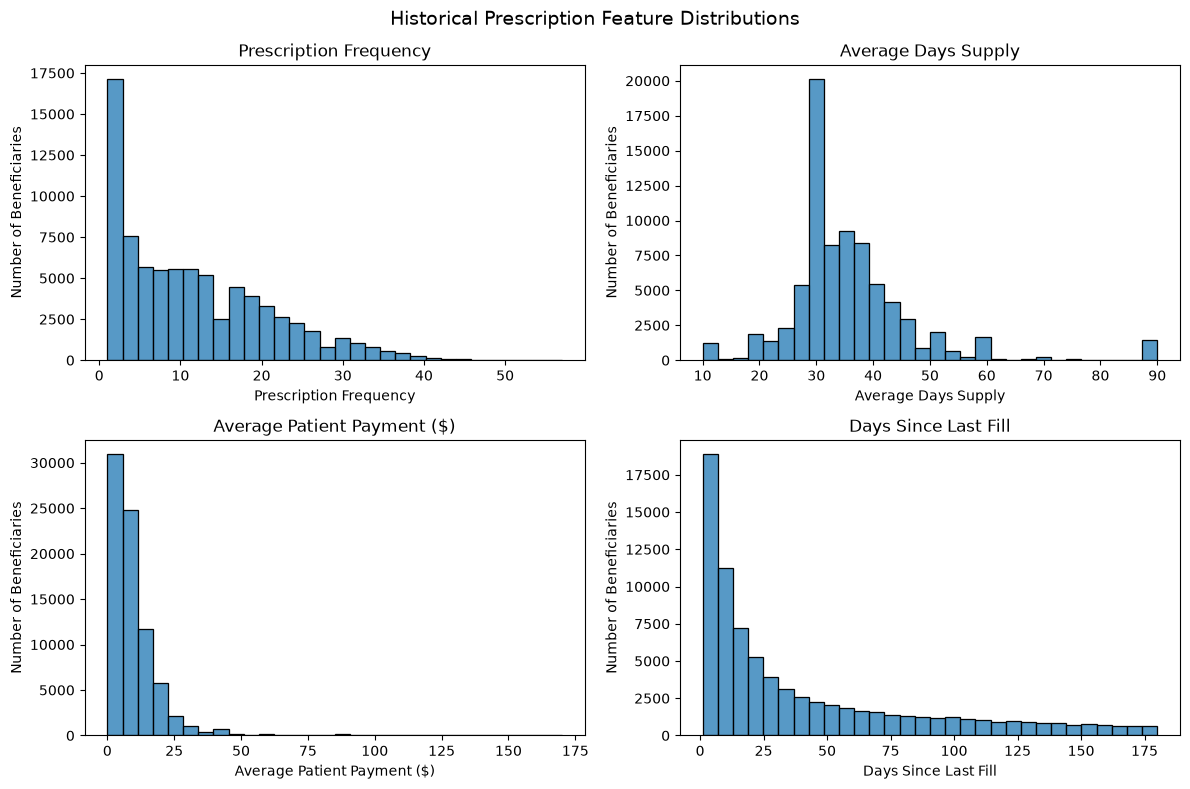

In [95]:
# Section 5.4 — Feature Distribution Analysis

features_to_plot = {
    "total_prescriptions_180d": "Prescription Frequency",
    "avg_days_supply_180d": "Average Days Supply",
    "avg_patient_payment_180d": "Average Patient Payment ($)",
    "days_since_last_fill": "Days Since Last Fill"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(
    axes.flatten(),
    features_to_plot.items()
):
    sns.histplot(
        data=df_patient_features,
        x=column,
        bins=30,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Number of Beneficiaries")

plt.suptitle(
    "Historical Prescription Feature Distributions",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Findings — Historical Feature Distributions

I visualized four engineered features to evaluate their distributions and identify potential preprocessing requirements.

**Key findings:**
- Prescription frequency was right-skewed, with most beneficiaries having relatively few prescription events.
- Average days supply was concentrated around 30–40 days, with additional observations at 90 days.
- Average patient payments were strongly right-skewed, with a smaller number of beneficiaries having substantially higher costs.
- Days since the last prescription was also right-skewed, with many beneficiaries showing recent prescription activity.

**Conclusion:**

The distributions indicated that several features have different scales and degrees of skewness.

For Logistic Regression, I applied standardization within the modeling pipeline; logarithmic transformations were not evaluated. Gradient Boosting served as a comparison model because it can capture nonlinear relationships without requiring feature standardization.

I retained the original feature values in the modeling dataset and applied scaling only within the preprocessing pipeline.

These distributions describe prescription behavior in synthetic data and do not independently establish medication adherence.

---
# 6. Target development | Simulating medication non-adherence

### 6.1 Simulated target | Generating binary outcomes

**Objective:** Create a reproducible, simulated 90-day medication non-adherence outcome for demonstrating supervised machine learning.

The CMS DE-SynPUF dataset contains synthetic prescription claims and modified medication identifiers, limiting its suitability for calculating a clinically validated medication adherence outcome.

For this proof of concept, I used historical prescription features to define a hypothetical non-adherence risk scenario and generated binary outcomes through probabilistic sampling.

The simulated target represents whether a beneficiary was classified as non-adherent during a hypothetical 90-day prediction period beginning July 1, 2010.

- **0:** Simulated adherent
- **1:** Simulated non-adherent

I used a fixed random seed to make the results reproducible.

In [96]:
# Section 6.1 — Simulated Non-Adherence Target

rng = np.random.default_rng(42)

# Historical predictors used in the simulation
payment = df_patient_features["avg_patient_payment_180d"]
recency = df_patient_features["days_since_last_fill"]
prescriptions = df_patient_features["total_prescriptions_180d"]
zero_day_flag = (
    df_patient_features["zero_day_events_180d"] > 0
).astype(int)

# Hypothetical risk assumptions — not estimated clinical effects
risk_score = (
    -1.1
    + 0.8 * np.log1p(payment / 10)
    + 1.2 * (recency / 90)
    + 0.4 * zero_day_flag
    - 0.6 * np.log1p(prescriptions / 5)
)

# Convert the score into a probability
simulated_probability = 1 / (1 + np.exp(-risk_score))

# Sample binary outcomes: 0 = adherent, 1 = non-adherent
df_patient_features["simulated_nonadherence_90d"] = (
    rng.binomial(1, simulated_probability)
)

# Review the simulated target distribution
target_summary = (
    df_patient_features["simulated_nonadherence_90d"]
    .value_counts()
    .rename(index={
        0: "Simulated adherent",
        1: "Simulated non-adherent"
    })
    .rename_axis("Outcome")
    .reset_index(name="Beneficiaries")
)

target_summary["Percentage"] = (
    target_summary["Beneficiaries"]
    / len(df_patient_features) * 100
).round(2)

display(target_summary)

,Outcome,Beneficiaries,Percentage
0,Simulated adherent,50183,63.75
1,Simulated non-adherent,28537,36.25


#### Findings — Simulated Target Distribution

I generated a reproducible binary non-adherence target for 78,720 beneficiaries using historical prescription features and predefined simulation assumptions.

**Key findings:**

- 50,183 beneficiaries (63.75%) were assigned to the simulated adherent class.
- 28,537 beneficiaries (36.25%) were assigned to the simulated non-adherent class.
- Both classes contained sufficient observations for model development.
- The majority-class baseline accuracy was 63.75%.

**Conclusion:**

The simulated target provided a controlled classification scenario for comparing Logistic Regression and Gradient Boosting.

I used stratified data splitting to preserve the target distribution across training, validation, and testing.

Because the target was generated using predefined relationships with historical features, model performance measured how effectively the algorithms recovered simulated patterns rather than demonstrating clinical prediction accuracy.

### 6.2 Modeling dataset | Feature selection and stratified splitting

**Objective:** Prepare a beneficiary-level classification dataset and separate it into training, validation, and test sets.

I used five historical prescription features for the baseline models, excluding the highly correlated NDC11 and NDC9 counts.

I applied stratified splitting to preserve the simulated target distribution and reserved the test set for final model evaluation.

Missing-value imputation and feature scaling were performed after splitting to prevent data leakage.

In [97]:
# Section 6.2 — Modeling Dataset and Train/Validation/Test Split

from sklearn.model_selection import train_test_split

# Select baseline predictive features
model_features = [
    "total_prescriptions_180d",
    "avg_days_supply_180d",
    "avg_patient_payment_180d",
    "zero_day_events_180d",
    "days_since_last_fill"
]

target_column = "simulated_nonadherence_90d"

X = df_patient_features[model_features].copy()
y = df_patient_features[target_column].copy()

# First split: reserve 20% for final testing
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 60% training and 20% validation overall
X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development
)

# Validate the split sizes and class proportions
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Beneficiaries": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage of Total": [
        round(len(X_train) / len(X) * 100, 2),
        round(len(X_val) / len(X) * 100, 2),
        round(len(X_test) / len(X) * 100, 2)
    ],
    "Simulated Non-Adherence (%)": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

display(split_summary)

,Dataset,Beneficiaries,Percentage of Total,Simulated Non-Adherence (%)
0,Training,47232,60.0,36.25
1,Validation,15744,20.0,36.25
2,Test,15744,20.0,36.25


#### Findings — Modeling Dataset Preparation

I prepared the beneficiary-level dataset for supervised classification using five historical prescription features.

**Key findings:**

- Training dataset: 47,232 beneficiaries (60%).
- Validation dataset: 15,744 beneficiaries (20%).
- Test dataset: 15,744 beneficiaries (20%).
- The simulated non-adherence rate remained 36.25% across all three datasets.

**Conclusion:**

I successfully created stratified training, validation, and test datasets while preserving the target distribution.

I reserved the test dataset for final evaluation and fit all preprocessing transformations using the training data only.

This approach supports reproducible model comparisons and prevents information from the validation or test datasets from influencing preprocessing.

---
# 7. Data preprocessing | Preparing features for machine learning

### 7.1 Preprocessing pipelines | Imputation and scaling

**Objective:** Define reproducible preprocessing pipelines that handle missing values and prepare numerical features for Logistic Regression and Gradient Boosting.

I used median imputation for missing average days-supply values and preserved missingness through an additional indicator feature.

For Logistic Regression, I standardized the numerical inputs to place them on comparable scales. Gradient Boosting used imputed features without scaling.

Both pipelines learned their preprocessing parameters exclusively from the training dataset to prevent data leakage.

In [98]:
# Section 7.1 — Define Preprocessing Pipelines

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Logistic Regression preprocessing
logistic_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Gradient Boosting preprocessing
boosting_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    )
])

# Check missing values before preprocessing
missing_by_split = pd.DataFrame({
    "Feature": model_features,
    "Training Missing": X_train.isna().sum().values,
    "Validation Missing": X_val.isna().sum().values,
    "Test Missing": X_test.isna().sum().values
})

display(missing_by_split)

,Feature,Training Missing,Validation Missing,Test Missing
0,total_prescriptions_180d,0,0,0
1,avg_days_supply_180d,134,58,60
2,avg_patient_payment_180d,0,0,0
3,zero_day_events_180d,0,0,0
4,days_since_last_fill,0,0,0


#### Findings — Preprocessing Validation

I evaluated missing values across the training, validation, and test datasets before fitting the preprocessing pipelines.

**Key findings:**

- Training data contained 134 missing average days-supply values.
- Validation data contained 58 missing values.
- Test data contained 60 missing values.
- All 252 previously identified missing values were accounted for.
- No other modeling features contained missing values.

**Conclusion:**

I established separate preprocessing pipelines for Logistic Regression and Gradient Boosting.

Both pipelines used median imputation and a missingness indicator. Logistic Regression also used feature standardization.

By fitting preprocessing within the training pipeline, I prevented validation and test data from influencing the transformations.

---
# 8. Model development | Training classification models

### 8.1 Logistic Regression | Establishing a baseline

**Objective:** Train an interpretable binary classification model using historical prescription features to predict the simulated non-adherence outcome.

I combined the previously defined preprocessing pipeline with Logistic Regression to ensure that imputation and standardization were learned from training data only.

I evaluated initial performance on the training and validation datasets using accuracy, precision, recall, F1-score, and ROC-AUC.

The model was intended to learn patterns in the simulated outcome, not to establish clinical prediction accuracy.

In [99]:
# Section 8.1 — Train Logistic Regression

# Combine preprocessing and classification
logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit the pipeline using training data only
logistic_model.fit(X_train, y_train)

# Generate predictions for training and validation
y_train_pred = logistic_model.predict(X_train)
y_val_pred = logistic_model.predict(X_val)

# Generate probabilities for ROC-AUC
y_train_prob = logistic_model.predict_proba(X_train)[:, 1]
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Calculate initial model performance
logistic_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Training": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred),
        roc_auc_score(y_train, y_train_prob)
    ],
    "Validation": [
        accuracy_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred, zero_division=0),
        recall_score(y_val, y_val_pred),
        f1_score(y_val, y_val_pred),
        roc_auc_score(y_val, y_val_prob)
    ]
}).round(4)

display(logistic_results)

,Metric,Training,Validation
0,Accuracy,0.7051,0.6995
1,Precision,0.6613,0.6518
2,Recall,0.3823,0.3671
3,F1-Score,0.4845,0.4697
4,ROC-AUC,0.7107,0.7026


#### Findings — Logistic Regression Baseline

I trained a Logistic Regression classifier using five historical prescription features and evaluated its performance on the training and validation datasets.

**Key findings:**

- Validation accuracy: 69.95%.
- Validation precision: 65.18%.
- Validation recall: 36.71%.
- Validation F1-score: 0.4697.
- Validation ROC-AUC: 0.7026.
- Accuracy exceeded the majority-class baseline of 63.75%.
- Training and validation performance were similar, with no substantial evidence of overfitting.

**Conclusion:**

Logistic Regression established an interpretable baseline for predicting the simulated non-adherence target.

Although the model performed better than the majority-class accuracy baseline, recall was relatively low at the default classification threshold.

I then compared these results against Gradient Boosting and evaluated whether threshold adjustments improved the balance between precision and recall.

Because the target was generated using a logistic probability function, these results reflect recovery of simulated relationships rather than validated clinical prediction performance.

### 8.2 Gradient Boosting | Evaluating nonlinear relationships

**Objective:** Train a Gradient Boosting classifier and compare its performance with the Logistic Regression baseline.

I used the same historical prescription features and data splits to maintain a consistent comparison.

Gradient Boosting used median imputation and missingness indicators without standardization. I evaluated accuracy, precision, recall, F1-score, and ROC-AUC on the training and validation datasets.

In [100]:
# Section 8.2 — Train Gradient Boosting

# Combine preprocessing and Gradient Boosting
boosting_model = Pipeline([
    ("preprocessor", boosting_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train using training data only
boosting_model.fit(X_train, y_train)

# Generate class predictions
y_train_pred_gb = boosting_model.predict(X_train)
y_val_pred_gb = boosting_model.predict(X_val)

# Generate predicted probabilities
y_train_prob_gb = boosting_model.predict_proba(X_train)[:, 1]
y_val_prob_gb = boosting_model.predict_proba(X_val)[:, 1]

# Calculate model performance
boosting_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Training": [
        accuracy_score(y_train, y_train_pred_gb),
        precision_score(y_train, y_train_pred_gb, zero_division=0),
        recall_score(y_train, y_train_pred_gb),
        f1_score(y_train, y_train_pred_gb),
        roc_auc_score(y_train, y_train_prob_gb)
    ],
    "Validation": [
        accuracy_score(y_val, y_val_pred_gb),
        precision_score(y_val, y_val_pred_gb, zero_division=0),
        recall_score(y_val, y_val_pred_gb),
        f1_score(y_val, y_val_pred_gb),
        roc_auc_score(y_val, y_val_prob_gb)
    ]
}).round(4)

display(boosting_results)

,Metric,Training,Validation
0,Accuracy,0.7085,0.6999
1,Precision,0.6604,0.6455
2,Recall,0.4033,0.3822
3,F1-Score,0.5008,0.4801
4,ROC-AUC,0.7158,0.7027


#### Findings — Gradient Boosting Model

I trained a Gradient Boosting classifier using the same historical prescription features and training/validation splits as Logistic Regression.

**Key findings:**

- Validation accuracy: 69.99%.
- Validation precision: 64.55%.
- Validation recall: 38.22%.
- Validation F1-score: 0.4801.
- Validation ROC-AUC: 0.7027.
- Training and validation results showed limited evidence of overfitting.

**Conclusion:**

Gradient Boosting achieved slightly higher recall and F1-score than Logistic Regression, but ROC-AUC performance was nearly identical.

The results suggested that the additional model complexity provided limited benefit for this simulated classification task.

I then compared both models using precision-recall performance before selecting a final model and evaluating alternative classification thresholds.

---
# 9. Model evaluation | Comparing classification performance

### 9.1 Validation comparison | Evaluating model discrimination

**Objective:** Compare Logistic Regression and Gradient Boosting using classification metrics and precision-recall performance.

I evaluated both models on the validation dataset using accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC.

This comparison helped determine whether the additional complexity of Gradient Boosting provided meaningful improvements over Logistic Regression before selecting a model for final testing.

In [101]:
# Section 9.1 — Validation Model Comparison

# Calculate average precision (summarizes the PR curve)
logistic_pr_auc = average_precision_score(
    y_val, y_val_prob
)

boosting_pr_auc = average_precision_score(
    y_val, y_val_prob_gb
)

# Combine existing validation results
validation_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Average Precision (PR-AUC)"
    ],
    "Logistic Regression": [
        *logistic_results["Validation"],
        logistic_pr_auc
    ],
    "Gradient Boosting": [
        *boosting_results["Validation"],
        boosting_pr_auc
    ]
}).round(4)

display(validation_comparison)

# Compare against the prevalence-based PR baseline
pr_baseline = pd.DataFrame({
    "Metric": [
        "Simulated positive-class prevalence",
        "Logistic Regression average precision",
        "Gradient Boosting average precision"
    ],
    "Value": [
        y_val.mean(),
        logistic_pr_auc,
        boosting_pr_auc
    ]
}).round(4)

display(pr_baseline)

,Metric,Logistic Regression,Gradient Boosting
0,Accuracy,0.6995,0.6999
1,Precision,0.6518,0.6455
2,Recall,0.3671,0.3822
3,F1-Score,0.4697,0.4801
4,ROC-AUC,0.7026,0.7027
5,Average Precision (PR-AUC),0.5988,0.5981


,Metric,Value
0,Simulated positive-class prevalence,0.3625
1,Logistic Regression average precision,0.5988
2,Gradient Boosting average precision,0.5981


#### Findings — Validation Model Comparison

I compared Logistic Regression and Gradient Boosting using accuracy, precision, recall, F1-score, ROC-AUC, and average precision.

**Key findings:**

- Both models achieved approximately 70% validation accuracy.
- Logistic Regression achieved an ROC-AUC of 0.7026 and average precision of 0.5988.
- Gradient Boosting achieved an ROC-AUC of 0.7027 and average precision of 0.5981.
- Both average precision scores exceeded the simulated positive-class prevalence baseline of 0.3625.
- Gradient Boosting provided slightly higher recall and F1-score at the default classification threshold.

**Conclusion:**

The two models demonstrated comparable discrimination, with limited additional benefit from Gradient Boosting.

I selected Logistic Regression for further evaluation because of its interpretability and comparable performance.

The relatively low recall at the default 0.50 threshold suggested that adjusting the classification threshold could improve identification of simulated non-adherent beneficiaries.

These results reflect simulated outcome relationships, not clinically validated adherence prediction.

### 9.2 Decision threshold optimization | Improving positive-case detection

**Objective:** Evaluate alternative Logistic Regression classification thresholds to improve the balance between precision and recall.

I compared decision thresholds using the validation dataset and measured changes in accuracy, precision, recall, F1-score, and the percentage of beneficiaries flagged as simulated non-adherent.

For this proof of concept, I selected the threshold that maximizes validation F1-score, balancing precision and recall without introducing an external intervention-cost assumption.

The final test dataset remained untouched until threshold selection was complete.

In [102]:
# Section 9.2 — Logistic Regression Threshold Optimization

# Evaluate alternative decision thresholds
thresholds = np.arange(0.15, 0.76, 0.05)

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into binary predictions
    predictions = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(y_val, predictions),
        "F1-Score": f1_score(y_val, predictions),
        "Flagged (%)": predictions.mean() * 100
    })

# Create comparison table
threshold_comparison = pd.DataFrame(
    threshold_results
)

display(threshold_comparison.round(4))

# Identify threshold with highest validation F1-score
best_index = threshold_comparison["F1-Score"].idxmax()

selected_threshold = float(
    threshold_comparison.loc[best_index, "Threshold"]
)

best_threshold_summary = threshold_comparison.loc[
    [best_index]
].copy()

display(best_threshold_summary.round(4))

,Threshold,Accuracy,Precision,Recall,F1-Score,Flagged (%)
0,0.15,0.3755,0.3663,0.9902,0.5348,97.9865
1,0.20,0.4411,0.3873,0.9311,0.5471,87.1443
2,0.25,0.5563,0.4389,0.8050,0.5681,66.4761
3,0.30,0.6413,0.5039,0.6828,0.5799,49.1235
4,0.35,0.6782,0.5542,0.5733,0.5636,37.5000
5,0.40,0.6908,0.5885,0.4889,0.5341,30.1131
6,0.45,0.6976,0.6219,0.4228,0.5034,24.6443
7,0.50,0.6995,0.6518,0.3671,0.4697,20.4141
8,0.55,0.6971,0.6804,0.3100,0.4259,16.5142
9,0.60,0.6924,0.7069,0.2586,0.3787,13.2622


,Threshold,Accuracy,Precision,Recall,F1-Score,Flagged (%)
3,0.3,0.6413,0.5039,0.6828,0.5799,49.1235


#### Findings — Decision Threshold Optimization

I evaluated Logistic Regression classification thresholds from 0.15 to 0.75 using the validation dataset.

**Key findings:**

- The default threshold of 0.50 produced 36.71% recall and an F1-score of 0.4697.
- The highest validation F1-score among the evaluated thresholds occurred at 0.30.
- At the selected threshold, recall increased to 68.28%.
- F1-score improved to 0.5799.
- Precision decreased to 50.39%.
- The proportion of beneficiaries flagged increased from 20.41% to 49.12%.

**Conclusion:**

Lowering the classification threshold substantially improved the model's ability to identify simulated non-adherent beneficiaries.

However, the improvement in recall came at the expense of precision and increased the number of beneficiaries flagged.

I selected a threshold of 0.30 because it maximized validation F1-score among the evaluated candidates, providing a defined and reproducible selection criterion.

In an operational healthcare application, threshold selection would also need to account for intervention capacity and the relative costs of false positives and false negatives.

### 9.3 Final test evaluation | Assessing the selected model

**Objective:** Evaluate the selected Logistic Regression model using the reserved test dataset and the validation-selected classification threshold of 0.30.

I measured accuracy, precision, recall, F1-score, ROC-AUC, and average precision on the test dataset.

I also examined the confusion matrix to understand false positives and false negatives.

The model and threshold were selected without using the test data. This evaluation assessed performance on unseen simulated outcomes rather than establish clinical predictive validity.

In [103]:
# Section 9.3 — Final Test Evaluation

# Generate test probabilities using the selected model
y_test_prob = logistic_model.predict_proba(X_test)[:, 1]

# Apply the validation-selected threshold
y_test_pred = (
    y_test_prob >= selected_threshold
).astype(int)

# Calculate final test metrics
test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Average Precision (PR-AUC)",
        "Beneficiaries Flagged (%)"
    ],
    "Final Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob),
        average_precision_score(y_test, y_test_prob),
        y_test_pred.mean() * 100
    ]
})

display(test_results.round(4))

# Create the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

confusion_table = pd.DataFrame(
    cm,
    index=[
        "Actual: Simulated Adherent",
        "Actual: Simulated Non-Adherent"
    ],
    columns=[
        "Predicted: Adherent",
        "Predicted: Non-Adherent"
    ]
)

display(confusion_table)

,Metric,Final Test
0,Accuracy,0.6406
1,Precision,0.5031
2,Recall,0.6830
3,F1-Score,0.5794
4,ROC-AUC,0.7141
5,Average Precision (PR-AUC),0.6135
6,Beneficiaries Flagged (%),49.2124


,Predicted: Adherent,Predicted: Non-Adherent
Actual: Simulated Adherent,6187,3850
Actual: Simulated Non-Adherent,1809,3898


#### Findings — Final Test Evaluation

I evaluated the selected Logistic Regression model on the reserved test dataset using the validation-selected threshold of 0.30.

**Key findings:**

- Test accuracy: 64.06%.
- Test precision: 50.31%.
- Test recall: 68.30%.
- Test F1-score: 0.5794.
- Test ROC-AUC: 0.7141.
- Test average precision: 0.6135.
- The model flagged 49.21% of beneficiaries as simulated non-adherent.

**Confusion matrix:**

- True positives: 3,898.
- True negatives: 6,187.
- False positives: 3,850.
- False negatives: 1,809.

**Conclusion:**

The final test results were consistent with validation performance, indicating limited evidence of overfitting or excessive threshold-selection bias.

The selected threshold improved positive-case detection, identifying approximately 68% of simulated non-adherent beneficiaries.

However, precision remained approximately 50%, meaning a substantial proportion of flagged cases were false positives.

Test accuracy (64.06%) was only slightly above the 63.75% majority-class baseline. I selected the 0.30 threshold to optimize F1-score and recall, not accuracy.

The results demonstrate a reproducible classification workflow, but they do not establish clinically validated medication non-adherence prediction. The labels were generated from predefined simulation assumptions rather than observed adherence outcomes.

### 9.4 Model interpretation | Understanding feature influence

**Objective:** Examine standardized Logistic Regression coefficients to understand how historical prescription features influence simulated non-adherence predictions.

I extracted the model coefficients, ranked features by their absolute magnitude, and evaluated the direction of their associations.

Because the target was generated from predefined risk assumptions, the resulting coefficients describe relationships learned from the simulation rather than clinically validated risk factors.

In [104]:
# Section 9.4 — Logistic Regression Feature Interpretation

# Retrieve fitted preprocessing and classifier components
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

# Retrieve feature names, including the missingness indicator
transformed_features = fitted_preprocessor.get_feature_names_out(
    model_features
)

# Extract standardized model coefficients
coefficient_summary = pd.DataFrame({
    "Feature": transformed_features,
    "Coefficient": fitted_classifier.coef_[0]
})

# Rank features by absolute coefficient magnitude
coefficient_summary["Absolute Coefficient"] = (
    coefficient_summary["Coefficient"].abs()
)

coefficient_summary["Direction"] = np.where(
    coefficient_summary["Coefficient"] > 0,
    "Positive",
    "Negative"
)

coefficient_summary = (
    coefficient_summary
    .sort_values("Absolute Coefficient", ascending=False)
    .reset_index(drop=True)
)

display(coefficient_summary.round(4))

,Feature,Coefficient,Absolute Coefficient,Direction
0,days_since_last_fill,0.6349,0.6349,Positive
1,avg_patient_payment_180d,0.3710,0.3710,Positive
2,total_prescriptions_180d,-0.2623,0.2623,Negative
3,zero_day_events_180d,0.1305,0.1305,Positive
4,missingindicator_avg_days_supply_180d,0.0214,0.0214,Positive
5,avg_days_supply_180d,-0.0044,0.0044,Negative


#### Findings — Model Interpretation

I examined the standardized Logistic Regression coefficients to understand which historical prescription features contributed most strongly to simulated non-adherence predictions.

**Key findings:**

- Days since the last fill had the largest positive coefficient (0.6349).
- Average patient payment had the second-largest positive coefficient (0.3710).
- Total prescription frequency showed a negative association (-0.2623).
- Zero-day prescription events had a smaller positive coefficient (0.1305).
- The missing days-supply indicator had limited influence (0.0214).
- Average days supply had a near-zero coefficient (-0.0044).

**Conclusion:**

The model recovered relationships consistent with the predefined assumptions used to generate the simulated outcome.

Prescription recency and patient payment were the strongest positive predictors, while greater prescription frequency was associated with lower simulated risk.

Average days supply contributed little to the model, which was expected because it was not directly used in the target-generation formula.

These coefficients demonstrate model interpretability within a controlled simulation. They should not be interpreted as clinically validated medication-adherence risk factors or causal relationships.

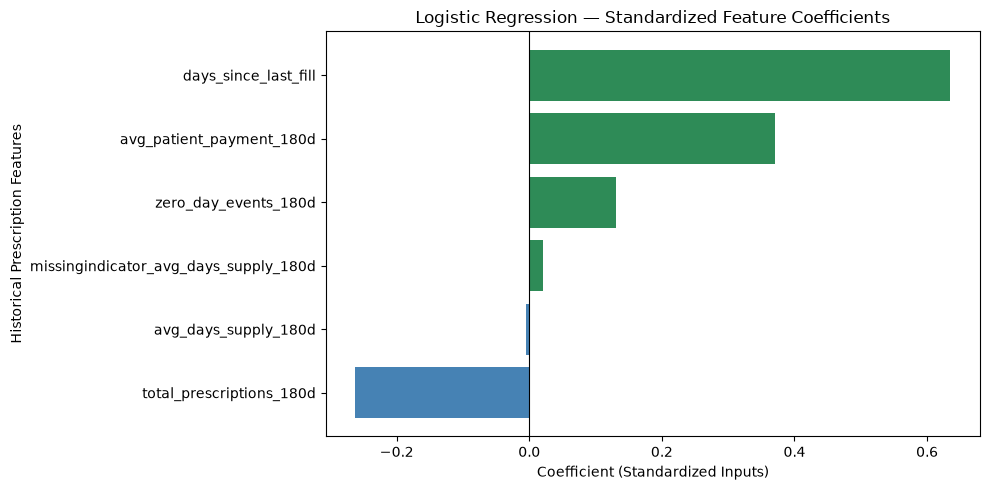

In [105]:
# Section 9.4 — Visualize Logistic Regression Coefficients

# Sort coefficients for horizontal visualization
plot_data = coefficient_summary.sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "seagreen" if value > 0 else "steelblue"
    for value in plot_data["Coefficient"]
]

ax.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Logistic Regression — Standardized Feature Coefficients"
)
ax.set_xlabel("Coefficient (Standardized Inputs)")
ax.set_ylabel("Historical Prescription Features")

plt.tight_layout()
plt.show()

---
# 10. Project conclusions | Results, limitations, and next steps


## 10.1 Project overview

I developed an end-to-end machine learning proof of concept using CMS Medicare Part D synthetic prescription claims.

The project included PostgreSQL data ingestion, SQL-based exploratory analysis, feature engineering, data validation, classification modeling, and model interpretation.

My goal was to demonstrate how historical prescription activity could support a supervised learning workflow while recognizing the limitations of synthetic healthcare data.

## 10.2 Data preparation and feature engineering

I processed 5,552,421 prescription drug events from the CMS DE-SynPUF dataset and created a beneficiary-level modeling dataset.

**Key accomplishments:**

- Loaded and validated prescription records using PostgreSQL and Python.
- Investigated medication identifiers at the NDC11 and NDC9 levels.
- Evaluated prescription refill continuity and identified limitations in the synthetic medication identifiers.
- Engineered seven numerical features using a 180-day historical observation window.
- Identified substantial redundancy among prescription frequency, NDC11 counts, and NDC9 counts.
- Investigated 252 missing average days-supply values and traced them to zero-day prescription records.
- Selected five historical features for baseline modeling.

The final modeling dataset contained 78,720 beneficiaries.

## 10.3 Predictive modeling approach

Because the synthetic medication identifiers did not support a clinically validated adherence target, I generated a reproducible simulated binary outcome using predefined risk assumptions.

I compared two classification algorithms:

1. Logistic Regression
2. Gradient Boosting

I used stratified training, validation, and test splits of 60%, 20%, and 20%, respectively.

Preprocessing included median imputation, missingness indicators, and standardization for Logistic Regression.

All learned preprocessing parameters were fitted using training data only.

## 10.4 Model evaluation results

Both models achieved comparable validation performance.

**Logistic Regression:**
- Validation ROC-AUC: 0.7026
- Validation average precision: 0.5988

**Gradient Boosting:**
- Validation ROC-AUC: 0.7027
- Validation average precision: 0.5981

I selected Logistic Regression because it offered comparable discrimination with greater interpretability.

I then evaluated classification thresholds using validation F1-score and selected a threshold of 0.30.

**Final test results:**

| Metric | Result |
|---|---:|
| Accuracy | 64.06% |
| Precision | 50.31% |
| Recall | 68.30% |
| F1-score | 0.5794 |
| ROC-AUC | 0.7141 |
| Average precision | 0.6135 |
| Beneficiaries flagged | 49.21% |

The selected threshold improved recall compared with the default threshold but increased false-positive classifications.

Validation and test performance were consistent.

## 10.5 Model interpretation

I examined standardized Logistic Regression coefficients to understand the relationships learned by the model.

The strongest positive associations with simulated non-adherence were:

- Days since the last prescription.
- Average patient payment.

Prescription frequency showed a negative association, while average days supply contributed little to predictions.

These relationships were consistent with the assumptions used to generate the simulated target.

## 10.6 Limitations

**This project is a machine learning proof of concept, not a clinically validated medication adherence prediction system.**

The primary limitations include:

- The CMS DE-SynPUF dataset contains synthetic claims and modified medication identifiers.
- NDC11 and NDC9 grouping could not establish clinically reliable therapeutic continuity.
- The non-adherence target was simulated rather than measured from observed future adherence.
- The simulated labels were generated using predefined relationships with historical features.
- Model metrics therefore measure recovery of simulated patterns, not real-world clinical predictive accuracy.
- Feature coefficients should not be interpreted as causal effects or independently discovered clinical risk factors.
- The selected decision threshold has not been evaluated against actual healthcare intervention costs or operational capacity.

These limitations prevent the results from supporting clinical decision-making or deployment.

## 10.7 Future improvements

With an appropriate real-world dataset, I would extend the project by:

1. Obtaining validated medication identifiers and therapeutic-class mappings.
2. Defining adherence outcomes using a clinically appropriate measure, such as proportion of days covered (PDC), where applicable.
3. Incorporating additional patient history, medication classes, and relevant clinical features.
4. Evaluating class imbalance, probability calibration, and intervention-specific decision thresholds.
5. Validating the model on independent data and assessing performance across relevant patient populations.

## 10.8 Final conclusion

I completed an end-to-end data science workflow that transformed millions of synthetic prescription events into a structured beneficiary-level dataset.

I demonstrated SQL-based analysis, feature engineering, data quality investigation, preprocessing, supervised classification, model comparison, threshold optimization, and feature interpretation.

The final Logistic Regression model achieved a test ROC-AUC of 0.7141, an F1-score of 0.5794, and recall of 68.30% against simulated outcomes.

The central result of this project is a reproducible and interpretable machine learning workflow rather than evidence of real-world medication non-adherence prediction.

The project also demonstrated the importance of validating data assumptions, identifying feature redundancy, preventing data leakage, selecting appropriate evaluation metrics, and clearly communicating modeling limitations.

## 10.9 Lessons Learned | What I Would Do Differently

For this project, I intentionally limited the initial analysis to the CMS Medicare Part D Prescription Drug Events dataset rather than integrating every available Medicare file.

My priority was to build a complete, reproducible machine learning workflow before increasing data complexity. By focusing on prescription claims, I was able to concentrate on SQL-based data preparation, refill-pattern analysis, feature engineering, data validation, model development, and evaluation.

This approach helped me identify several important challenges, particularly the limitations of synthetic medication identifiers, the scarcity of repeated prescription records, and the difficulty of defining a clinically valid medication non-adherence target.

**What I would do differently:**

**1. Expand the data sources**

I would incorporate the 2008, 2009, and appropriately selected 2010 Beneficiary Summary data to introduce additional historical and demographic context.

This could include age, chronic-condition indicators, Medicare enrollment information, and prior-year healthcare utilization.

I would join these datasets using the beneficiary identifier and ensure that every predictive feature was available before the prediction date.

**2. Improve the target definition**

The most significant improvement would be obtaining reliable longitudinal medication data and validated drug identifiers.

This would allow me to calculate a clinically appropriate medication adherence measure, such as proportion of days covered (PDC), instead of relying on simulated outcomes.

**3. Evaluate additional features and models**

I would compare the prescription-only baseline against a model incorporating beneficiary demographics, chronic conditions, and historical healthcare utilization.

I would use feature selection and model interpretation to determine whether those additions improve predictive performance.

**4. Strengthen clinical and operational validation**

I would validate model performance against observed outcomes, examine results across relevant patient populations, and select classification thresholds based on the costs and benefits of potential interventions.

**Final Reflection:**

The most important lesson from this project was that building a machine learning model involves more than selecting an algorithm.

Data quality, feature relevance, target validity, leakage prevention, and the interpretation of results are equally important.

Starting with a single dataset allowed me to establish the technical foundation and identify meaningful limitations before introducing additional complexity.

The next iteration would build on that foundation by integrating beneficiary-level information and replacing the simulated target with a validated adherence outcome.